# Bike Sharing in the Bay Area

We end this chapter by using all the methods we have learned to examine a new and large dataset. We will also draw maps of the bike stations.

The [Bay Area Bike Share](http://www.bayareabikeshare.com/) service published a [dataset](http://www.bayareabikeshare.com/open-data) describing every bicycle rental from September 2014 to August 2015 in their system. There were 354,152 rentals in all. The columns are:

- An ID for the rental
- Duration of the rental, in seconds
- Start date
- Name of the Start Station and code for Start Terminal
- Name of the End Station and code for End Terminal
- A serial number for the bike
- Subscriber type and zip code

In [1]:
import polars as pl
%matplotlib inline
path_data = '../../../assets/data/'
import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')
import math
from scipy import stats
import folium

In [2]:
# POLARS_CHANGE: some zip codes are the text "nil", so that column is read as strings
trips = pl.read_csv(path_data + "trip.csv", schema_overrides={"Zip Code": pl.String})
trips

Trip ID,Duration,Start Date,Start Station,Start Terminal,End Date,End Station,End Terminal,Bike #,Subscriber Type,Zip Code
i64,i64,str,str,i64,str,str,i64,i64,str,str
913460,765,"""8/31/2015 23:26""","""Harry Bridges Plaza (Ferry Bui…",50,"""8/31/2015 23:39""","""San Francisco Caltrain (Townse…",70,288,"""Subscriber""","""2139"""
913459,1036,"""8/31/2015 23:11""","""San Antonio Shopping Center""",31,"""8/31/2015 23:28""","""Mountain View City Hall""",27,35,"""Subscriber""","""95032"""
913455,307,"""8/31/2015 23:13""","""Post at Kearny""",47,"""8/31/2015 23:18""","""2nd at South Park""",64,468,"""Subscriber""","""94107"""
913454,409,"""8/31/2015 23:10""","""San Jose City Hall""",10,"""8/31/2015 23:17""","""San Salvador at 1st""",8,68,"""Subscriber""","""95113"""
913453,789,"""8/31/2015 23:09""","""Embarcadero at Folsom""",51,"""8/31/2015 23:22""","""Embarcadero at Sansome""",60,487,"""Customer""","""9069"""
…,…,…,…,…,…,…,…,…,…,…
432951,619,"""9/1/2014 4:21""","""Powell Street BART""",39,"""9/1/2014 4:32""","""Townsend at 7th""",65,335,"""Subscriber""","""94118"""
432950,6712,"""9/1/2014 3:16""","""Harry Bridges Plaza (Ferry Bui…",50,"""9/1/2014 5:08""","""San Francisco Caltrain (Townse…",70,259,"""Customer""","""44100"""
432949,538,"""9/1/2014 0:05""","""South Van Ness at Market""",66,"""9/1/2014 0:14""","""5th at Howard""",57,466,"""Customer""","""32"""


We'll focus only on the *free trips*, which are trips that last less than 1800 seconds (half an hour). There is a charge for longer trips.

The histogram below shows that most of the trips took around 10 minutes (600 seconds) or so. Very few took near 30 minutes (1800 seconds), possibly because people try to return the bikes before the cutoff time so as not to have to pay.

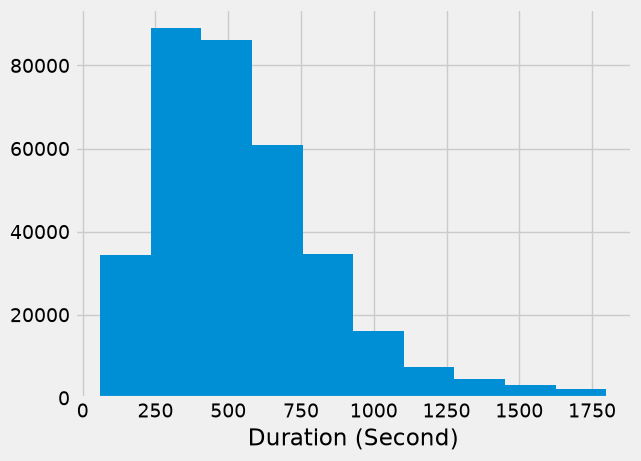

In [3]:
commute = trips.filter(pl.col("Duration") < 1800)
# POLARS_CHANGE: unit="Second" was the horizontal axis label
plt.hist(commute.get_column("Duration"), bins=10)
plt.xlabel("Duration (Second)");

We can get more detail by specifying a larger number of bins. But the overall shape doesn't change much.

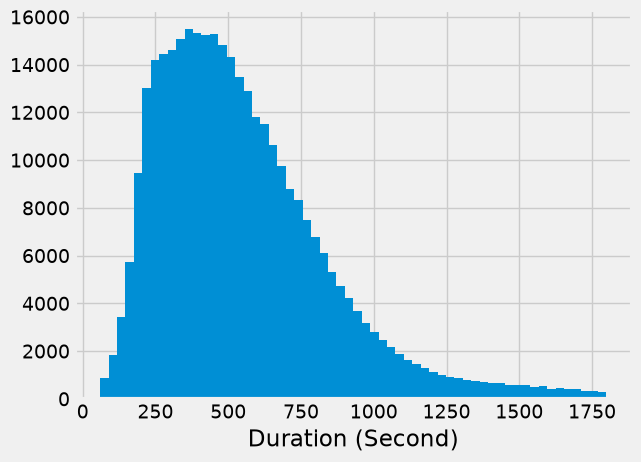

In [4]:
plt.hist(commute.get_column("Duration"), bins=60)
plt.xlabel("Duration (Second)");

## Exploring the Data with `group` and `pivot`

We can use `group` to identify the most highly used Start Station:

In [5]:
starts = commute.group_by("Start Station").len(name="count").sort("count", descending=True)
starts

Start Station,count
str,u32
"""San Francisco Caltrain (Townse…",25858
"""San Francisco Caltrain 2 (330 …",21523
"""Harry Bridges Plaza (Ferry Bui…",15543
"""Temporary Transbay Terminal (H…",14298
"""2nd at Townsend""",13674
…,…
"""Mezes Park""",189
"""Redwood City Medical Center""",139
"""San Mateo County Center""",108


The largest number of trips started at the Caltrain Station on Townsend and 4th in San Francisco. People take the train into the city, and then use a shared bike to get to their next destination.

The `group` method can also be used to classify the rentals by both Start Station and End Station.

In [6]:
commute.group_by(["Start Station", "End Station"]).len(name="count").sort("count", descending=True)

Start Station,End Station,count
str,str,u32
"""San Francisco Caltrain 2 (330 …","""Townsend at 7th""",3737
"""2nd at Townsend""","""Harry Bridges Plaza (Ferry Bui…",2947
"""Harry Bridges Plaza (Ferry Bui…","""Embarcadero at Sansome""",2729
"""Townsend at 7th""","""San Francisco Caltrain 2 (330 …",2723
"""Harry Bridges Plaza (Ferry Bui…","""2nd at Townsend""",2607
…,…,…
"""San Antonio Shopping Center""","""Cowper at University""",1
"""Mountain View Caltrain Station""","""California Ave Caltrain Statio…",1
"""Redwood City Medical Center""","""Stanford in Redwood City""",1


Fifty-four trips both started and ended at the station on 2nd at Folsom. A much large number (437) were between 2nd at Folsom and 2nd at Townsend. 

The `pivot` method does the same classification but displays its results in a contingency table that shows all possible combinations of Start and End Stations, even though some of them didn't correspond to any trips. Remember that the first argument of `pivot` specifies the column labels of the pivot table; `index` labels the rows.

There is a train station as well as a Bay Area Rapid Transit (BART) station near Beale at Market, explaining the high number of trips that start and end there.

In [7]:
station_counts = commute.pivot("Start Station", index="End Station", aggregate_function="len")
value_cols = sorted(col for col in station_counts.columns if col != "End Station")
station_counts.select("End Station", *value_cols).sort("End Station")

End Station,Bike #_2nd at Folsom,Bike #_2nd at South Park,Bike #_2nd at Townsend,Bike #_5th at Howard,Bike #_Adobe on Almaden,Bike #_Arena Green / SAP Center,Bike #_Beale at Market,Bike #_Broadway St at Battery St,Bike #_California Ave Caltrain Station,Bike #_Castro Street and El Camino Real,Bike #_Civic Center BART (7th at Market),Bike #_Clay at Battery,Bike #_Commercial at Montgomery,Bike #_Cowper at University,Bike #_Davis at Jackson,Bike #_Embarcadero at Bryant,Bike #_Embarcadero at Folsom,Bike #_Embarcadero at Sansome,Bike #_Embarcadero at Vallejo,Bike #_Evelyn Park and Ride,Bike #_Franklin at Maple,Bike #_Golden Gate at Polk,Bike #_Grant Avenue at Columbus Avenue,Bike #_Harry Bridges Plaza (Ferry Building),Bike #_Howard at 2nd,Bike #_Japantown,Bike #_MLK Library,Bike #_Market at 10th,Bike #_Market at 4th,Bike #_Market at Sansome,Bike #_Mechanics Plaza (Market at Battery),Bike #_Mezes Park,Bike #_Mountain View Caltrain Station,Bike #_Mountain View City Hall,Bike #_Palo Alto Caltrain Station,Bike #_Park at Olive,…,Zip Code_Mountain View City Hall,Zip Code_Palo Alto Caltrain Station,Zip Code_Park at Olive,Zip Code_Paseo de San Antonio,Zip Code_Post at Kearny,Zip Code_Powell Street BART,Zip Code_Powell at Post (Union Square),Zip Code_Redwood City Caltrain Station,Zip Code_Redwood City Medical Center,Zip Code_Redwood City Public Library,Zip Code_Rengstorff Avenue / California Street,Zip Code_Ryland Park,Zip Code_SJSU - San Salvador at 9th,Zip Code_SJSU 4th at San Carlos,Zip Code_San Antonio Caltrain Station,Zip Code_San Antonio Shopping Center,Zip Code_San Francisco Caltrain (Townsend at 4th),Zip Code_San Francisco Caltrain 2 (330 Townsend),Zip Code_San Francisco City Hall,Zip Code_San Jose City Hall,Zip Code_San Jose Civic Center,Zip Code_San Jose Diridon Caltrain Station,Zip Code_San Mateo County Center,Zip Code_San Pedro Square,Zip Code_San Salvador at 1st,Zip Code_Santa Clara County Civic Center,Zip Code_Santa Clara at Almaden,Zip Code_South Van Ness at Market,Zip Code_Spear at Folsom,Zip Code_St James Park,Zip Code_Stanford in Redwood City,Zip Code_Steuart at Market,Zip Code_Temporary Transbay Terminal (Howard at Beale),Zip Code_Townsend at 7th,Zip Code_University and Emerson,Zip Code_Washington at Kearny,Zip Code_Yerba Buena Center of the Arts (3rd @ Howard)
str,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,…,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
"""2nd at Folsom""",54,190,554,107,0,0,40,21,0,0,44,78,54,0,9,77,32,41,14,0,0,11,30,416,53,0,0,169,114,302,33,0,0,0,0,0,…,0,0,0,0,60,121,88,0,0,0,0,0,0,0,0,0,694,445,21,0,0,0,0,0,0,0,0,38,57,0,0,39,237,342,0,17,31
"""2nd at South Park""",295,164,71,180,0,0,208,85,0,0,112,87,160,0,37,56,178,83,116,0,0,57,73,574,500,0,0,139,199,1633,119,0,0,0,0,0,…,0,0,0,0,299,84,113,0,0,0,0,0,0,0,0,0,559,480,48,0,0,0,0,0,0,0,0,66,152,0,0,374,429,143,0,63,209
"""2nd at Townsend""",437,151,185,92,0,0,608,350,0,0,80,329,168,0,386,361,658,506,254,0,0,27,315,2607,295,0,0,110,225,845,177,0,0,0,0,0,…,0,0,0,0,120,100,141,0,0,0,0,0,0,0,0,0,905,299,14,0,0,0,0,0,0,0,0,72,508,0,0,2349,784,417,0,57,166
"""5th at Howard""",113,177,148,83,0,0,59,130,0,0,203,76,129,0,30,57,49,166,54,0,0,85,78,371,478,0,0,303,158,168,90,0,0,0,0,0,…,0,0,0,0,93,183,169,0,0,0,0,0,0,0,0,0,690,1859,48,0,0,0,0,0,0,0,0,116,102,0,0,182,750,200,0,43,267
"""Adobe on Almaden""",0,0,0,0,11,4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,17,7,0,0,0,0,0,0,0,0,0,…,0,0,0,25,0,0,0,0,0,0,0,7,7,16,0,0,0,0,0,19,23,265,0,20,4,5,10,0,0,14,0,0,0,0,0,0,0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""Temporary Transbay Terminal (H…",414,437,486,561,0,0,531,549,0,0,320,313,542,0,259,198,66,651,321,0,0,319,447,257,61,0,0,227,725,265,133,0,0,0,0,0,…,0,0,0

We can also use `pivot` to find the shortest time of the rides between Start and End Stations. Here `pivot` has been given `Duration` as the optional `values` argument, and `min` as the function which to perform on the values in each cell.

In [8]:
shortest = commute.pivot(
    "Start Station",
    index="End Station",
    values="Duration",
    aggregate_function="min",
)
value_cols = sorted(col for col in shortest.columns if col != "End Station")
shortest.select("End Station", *value_cols).sort("End Station")

End Station,2nd at Folsom,2nd at South Park,2nd at Townsend,5th at Howard,Adobe on Almaden,Arena Green / SAP Center,Beale at Market,Broadway St at Battery St,California Ave Caltrain Station,Castro Street and El Camino Real,Civic Center BART (7th at Market),Clay at Battery,Commercial at Montgomery,Cowper at University,Davis at Jackson,Embarcadero at Bryant,Embarcadero at Folsom,Embarcadero at Sansome,Embarcadero at Vallejo,Evelyn Park and Ride,Franklin at Maple,Golden Gate at Polk,Grant Avenue at Columbus Avenue,Harry Bridges Plaza (Ferry Building),Howard at 2nd,Japantown,MLK Library,Market at 10th,Market at 4th,Market at Sansome,Mechanics Plaza (Market at Battery),Mezes Park,Mountain View Caltrain Station,Mountain View City Hall,Palo Alto Caltrain Station,Park at Olive,Paseo de San Antonio,Post at Kearny,Powell Street BART,Powell at Post (Union Square),Redwood City Caltrain Station,Redwood City Medical Center,Redwood City Public Library,Rengstorff Avenue / California Street,Ryland Park,SJSU - San Salvador at 9th,SJSU 4th at San Carlos,San Antonio Caltrain Station,San Antonio Shopping Center,San Francisco Caltrain (Townsend at 4th),San Francisco Caltrain 2 (330 Townsend),San Francisco City Hall,San Jose City Hall,San Jose Civic Center,San Jose Diridon Caltrain Station,San Mateo County Center,San Pedro Square,San Salvador at 1st,Santa Clara County Civic Center,Santa Clara at Almaden,South Van Ness at Market,Spear at Folsom,St James Park,Stanford in Redwood City,Steuart at Market,Temporary Transbay Terminal (Howard at Beale),Townsend at 7th,University and Emerson,Washington at Kearny,Yerba Buena Center of the Arts (3rd @ Howard)
str,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64
"""2nd at Folsom""",61,97,164,268,null,null,271,407,null,null,483,329,306,null,494,239,262,687,599,null,null,639,416,282,80,null,null,506,237,167,250,null,null,null,null,null,null,208,264,290,null,null,null,null,null,null,null,null,null,300,303,584,null,null,null,null,null,null,null,null,590,208,null,null,318,149,448,null,429,165
"""2nd at South Park""",61,60,77,86,null,null,78,345,null,null,290,188,171,null,357,104,81,490,341,null,null,369,278,122,60,null,null,416,142,61,68,null,null,null,null,null,null,60,237,106,null,null,null,null,null,null,null,null,null,63,66,458,null,null,null,null,null,null,null,null,399,63,null,null,79,61,78,null,270,96
"""2nd at Townsend""",137,67,60,423,null,null,311,469,null,null,546,520,474,null,436,145,232,509,494,null,null,773,549,325,221,null,null,667,367,265,395,null,null,null,null,null,null,319,455,398,null,null,null,null,null,null,null,null,null,125,133,742,null,null,null,null,null,null,null,null,777,241,null,null,291,249,259,null,610,284
"""5th at Howard""",215,300,384,68,null,null,357,530,null,null,179,412,364,null,543,419,359,695,609,null,null,235,474,453,145,null,null,269,161,250,306,null,null,null,null,null,null,234,89,202,null,null,null,null,null,null,null,null,null,256,221,347,null,null,null,null,null,null,null,null,375,402,null,null,455,265,357,null,553,109
"""Adobe on Almaden""",null,null,null,null,84,275,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,701,387,null,null,null,null,null,null,null,null,null,229,null,null,null,null,null,null,null,441,452,318,null,null,null,null,null,309,146,182,null,207,358,876,101,null,null,369,null,null,null,null,null,null,null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""Temporary Transbay Terminal (H…",112,195,261,279,null,null,68,261,null,null,385,181,225,null,221,157,128,385,264,null,null,468,326,171,114,null,null,562,248,155,119,null,null,null,null,null,null,219,322,361,null,null,null,null,null,null,nu

Someone had a very quick trip (271 seconds, or about 4.5 minutes) from Beale at Market to 2nd at Folsom, about five blocks away. There are no bike trips between the 2nd Avenue stations and Adobe on Almaden, because the latter is in a different city.

## Drawing Maps
The DataFrame `stations` contains geographical information about each bike station, including latitude, longitude, and a "landmark" which is the name of the city where the station is located.

In [9]:
stations = pl.read_csv(path_data + "station.csv")
stations

station_id,name,lat,long,dockcount,landmark,installation
i64,str,f64,f64,i64,str,str
2,"""San Jose Diridon Caltrain Stat…",37.329732,-121.901782,27,"""San Jose""","""8/6/2013"""
3,"""San Jose Civic Center""",37.330698,-121.888979,15,"""San Jose""","""8/5/2013"""
4,"""Santa Clara at Almaden""",37.333988,-121.894902,11,"""San Jose""","""8/6/2013"""
5,"""Adobe on Almaden""",37.331415,-121.8932,19,"""San Jose""","""8/5/2013"""
6,"""San Pedro Square""",37.336721,-121.894074,15,"""San Jose""","""8/7/2013"""
…,…,…,…,…,…,…
77,"""Market at Sansome""",37.789625,-122.400811,27,"""San Francisco""","""8/25/2013"""
80,"""Santa Clara County Civic Cente…",37.352601,-121.905733,15,"""San Jose""","""12/31/2013"""
82,"""Broadway St at Battery St""",37.798541,-122.400862,15,"""San Francisco""","""1/22/2014"""


We can draw a map of where the stations are located. The DataFrame's columns are, in order, latitude, longitude, and an optional identifier for each point.

In [10]:
# POLARS_CHANGE: Polars does not draw maps, so folium places one marker per station
points = stations.select("lat", "long", "name").rename({"name": "labels"})
station_map = folium.Map(
    location=[points.get_column("lat").mean(), points.get_column("long").mean()],
    zoom_start=10,
)
for lat, lon, name in points.iter_rows():
    folium.Marker([lat, lon], popup=name).add_to(station_map)
station_map

The map is created using [OpenStreetMap](http://www.openstreetmap.org/#map=5/51.500/-0.100), which is an open online mapping system that you can use just as you would use Google Maps or any other online map. Zoom in to San Francisco to see how the stations are distributed. Click on a marker to see which station it is.

You can also represent points on a map by colored circles. Here is such a map of the San Francisco bike stations.

In [11]:
sf = stations.filter(pl.col("landmark") == "San Francisco")
sf_map_data = sf.select("lat", "long", "name").rename({"name": "labels"})
sf_map = folium.Map(
    location=[sf_map_data.get_column("lat").mean(), sf_map_data.get_column("long").mean()],
    zoom_start=13,
)
for lat, lon, name in sf_map_data.iter_rows():
    folium.CircleMarker([lat, lon], popup=name, color="green", fill=True, radius=10).add_to(sf_map)
sf_map

## More Informative Maps: An Application of `join`
The bike stations are located in five different cities in the Bay Area. To distinguish the points by using a different color for each city, let's start by using group to identify all the cities and assign each one a color.

In [12]:
# POLARS_CHANGE: group_by does not sort, so cities are sorted before the colors are assigned
cities = stations.group_by("landmark").len(name="count").sort("landmark").rename({"landmark": "city"})
cities

city,count
str,u32
"""Mountain View""",7
"""Palo Alto""",5
"""Redwood City""",7
"""San Francisco""",35
"""San Jose""",16


In [13]:
colors = cities.with_columns(
    pl.Series("color", ["blue", "red", "green", "orange", "purple"])
)
colors

city,count,color
str,u32,str
"""Mountain View""",7,"""blue"""
"""Palo Alto""",5,"""red"""
"""Redwood City""",7,"""green"""
"""San Francisco""",35,"""orange"""
"""San Jose""",16,"""purple"""


Now we can join `stations` and `colors` by `landmark`, and then select the columns we need to draw a map.

In [14]:
joined = stations.join(colors, left_on="landmark", right_on="city")
colored = joined.select("lat", "long", "name", "color").rename({"name": "labels"})
colored_map = folium.Map(
    location=[colored.get_column("lat").mean(), colored.get_column("long").mean()],
    zoom_start=10,
)
for lat, lon, name, color in colored.iter_rows():
    folium.Marker([lat, lon], popup=name, icon=folium.Icon(color=color)).add_to(colored_map)
colored_map

Now the markers have five different colors for the five different cities.

To see where most of the bike rentals originate, let's identify the start stations:

In [15]:
starts = commute.group_by("Start Station").len(name="count").sort("count", descending=True)
starts

Start Station,count
str,u32
"""San Francisco Caltrain (Townse…",25858
"""San Francisco Caltrain 2 (330 …",21523
"""Harry Bridges Plaza (Ferry Bui…",15543
"""Temporary Transbay Terminal (H…",14298
"""2nd at Townsend""",13674
…,…
"""Mezes Park""",189
"""Redwood City Medical Center""",139
"""San Mateo County Center""",108


We can include the geographical data needed to map these stations, by first joining `starts` with `stations`:

In [16]:
station_starts = stations.join(starts, left_on="name", right_on="Start Station").sort("name")
station_starts

station_id,name,lat,long,dockcount,landmark,installation,count
i64,str,f64,f64,i64,str,str,u32
62,"""2nd at Folsom""",37.785299,-122.396236,19,"""San Francisco""","""8/22/2013""",7841
64,"""2nd at South Park""",37.782259,-122.392738,15,"""San Francisco""","""8/22/2013""",9274
61,"""2nd at Townsend""",37.780526,-122.390288,27,"""San Francisco""","""8/22/2013""",13674
57,"""5th at Howard""",37.781752,-122.405127,15,"""San Francisco""","""8/21/2013""",7394
5,"""Adobe on Almaden""",37.331415,-121.8932,19,"""San Jose""","""8/5/2013""",522
…,…,…,…,…,…,…,…
74,"""Steuart at Market""",37.794139,-122.394434,23,"""San Francisco""","""8/25/2013""",13215
55,"""Temporary Transbay Terminal (H…",37.789756,-122.394643,23,"""San Francisco""","""8/20/2013""",14298
65,"""Townsend at 7th""",37.771058,-122.402717,15,"""San Francisco""","""8/22/2013""",13579


Now we extract just the data needed for drawing our map, adding a color and an area to each station. The area is 0.3 times the count of the number of rentals starting at each station, where the constant 0.3 was chosen so that the circles would appear at an appropriate scale on the map.

In [17]:
starts_map_data = station_starts.select("lat", "long", "name").with_columns(
    pl.lit("blue").alias("colors"),
    (station_starts.get_column("count") * 0.3).alias("areas"),
).rename({"name": "labels"})
display(starts_map_data.head(3))
starts_map = folium.Map(
    location=[starts_map_data.get_column("lat").mean(), starts_map_data.get_column("long").mean()],
    zoom_start=10,
)
for lat, lon, name, color, area in starts_map_data.iter_rows():
    folium.CircleMarker(
        [lat, lon],
        popup=name,
        color=color,
        fill=True,
        radius=(area / math.pi) ** 0.5,
    ).add_to(starts_map)
starts_map

lat,long,labels,colors,areas
f64,f64,str,str,f64
37.785299,-122.396236,"""2nd at Folsom""","""blue""",2352.3
37.782259,-122.392738,"""2nd at South Park""","""blue""",2782.2
37.780526,-122.390288,"""2nd at Townsend""","""blue""",4102.2


That huge blob in San Francisco shows that the eastern section of the city is the unrivaled capital of bike rentals in the Bay Area.